# Bloc A – Les annulations

## Le fil rouge
Une seule question derrière tout le bloc : **qu'est-ce qui fait qu'un client annule, et peut-on le prévoir ?**
- **Q1** cherche *quelles* informations comptent.
- **Q2** étudie la plus importante : le délai.
- **Q5** s'en sert pour *prévoir* les annulations.

**Repère pour tout le bloc** : 26 % des réservations sont annulées. Chaque taux se compare à ce chiffre.

---

## Q1 – Qu'est-ce qui distingue une annulation ?

**Point de départ** : deux avis s'opposent.
- Le revenue manager : « ce sont les plateformes (OTA) ».
- Les directeurs : « c'est la clientèle loisir ».

**Logique** : on ne croit personne, on vérifie avec les données.

**Étape 1 – Tout comparer**
- On compare chaque colonne entre réservations annulées et honorées.
- Résultat : **seul le délai change vraiment** (52 jours contre 22).
- → On sait déjà où chercher.

**Preuve 1 – Les taux par canal et par segment**
- OTA : 27,7 %, à peine au-dessus de la moyenne.
- Affaires 16 % contre loisir et groupe 33 % : un vrai écart.
- → Le segment compte plus que le canal.

**Preuve 2 – À segment égal**
- Pourquoi : si les OTA avaient surtout des clients loisir, elles paraîtraient « mauvaises » à cause de leurs clients.
- On compare donc les canaux entre clients du même type.
- Résultat : chez les affaires, les OTA annulent même *moins*.
- → Le canal n'a pas d'effet régulier.

**Preuve 3 – À délai égal**
- Pourquoi : les clients loisir réservent beaucoup plus tôt (55 jours contre 9).
- On compare les canaux entre réservations faites aussi longtemps à l'avance.
- Résultat : les OTA sont dans la moyenne… sauf au-delà de 60 jours (48 % contre 34 %).
- → Le vrai risque : réserver très tôt, surtout sur une plateforme.

**Conclusion** : ce n'est pas le canal, c'est surtout **le délai de réservation**.

---

## Q2 – Réserver tôt, est-ce sûr ?

**Logique** : la Q1 dit *que* le délai compte. La Q2 dit *comment* et *à partir de quand*.

- On découpe le délai en 5 tranches (de 0-7 jours à plus de 120 jours).
- Résultat : le taux monte à chaque tranche, **de 16 % à 67 %**.
- Vérification à segment égal : l'effet existe aussi chez les clients loisir et groupe.
- → **C'est l'inverse de l'idée reçue.**
- → Le risque devient fort **au-delà de 60 jours** : c'est là qu'il faut agir.

---

## Q5 – Peut-on prédire une annulation ?

**Logique** : on a trouvé le facteur clé, on construit un outil qui l'utilise. La réponse est oui/non : c'est une **classification** → **kNN** (séance 4).

**1. Séparer apprentissage et test**
- 70 % pour apprendre, 30 % pour juger.
- → Un modèle ne se note jamais sur ce qu'il a appris.

**2. Le piège de l'exactitude**
- Un modèle qui dit « pas d'annulation » à tout le monde a déjà 74 % de bonnes réponses.
- Le kNN atteint ce score… sans détecter aucune annulation.
- → L'exactitude ment : on regarde le **rappel** et la **précision**.

**3. Rééquilibrer, puis choisir k**
- Autant d'annulées que d'honorées, comme dans le cours → 50 % = hasard.
- Meilleur réglage : **délai seul, k = 51**.
- Ajouter d'autres colonnes fait *baisser* le score.
- → Confirme la Q1 : le délai porte l'information.

**4. Juger sur le test**
- Le modèle détecte **58 % des annulations**.
- Quand il annonce une annulation, il a raison 38 % du temps (contre 26 % au hasard).
- → Utile, mais pas assez fiable pour juger un client seul.

**5. Vérifier la fuite d'information**
- Le cumul client pourrait être calculé après l'annulation.
- Avec ou sans lui : même score.
- → Pas de fuite, pas de gain : on l'exclut.

**6. Préparer le bloc C**
- Une probabilité d'annulation pour chaque réservation.
- Elle est juste en moyenne (26,3 % prédit contre 25,9 % réel).
- → Le bloc C l'utilise pour décider combien de chambres survendre.

---

## Ce qu'on recommande
- Ne pas pénaliser les plateformes.
- Acompte ou tarif non remboursable **au-delà de 60 jours**.
- Utiliser le modèle pour estimer le nombre d'annulations **par hôtel**, pas pour juger un client.

In [39]:
#les imports
import glob                       # trouver les fichiers dans Colab
import pandas as pd               # tableaux : groupby, pivot_table, merge, cut
import matplotlib.pyplot as plt   # graphiques

In [40]:
df = pd.read_csv(glob.glob('/content/**/reservations_propres_800*.csv', recursive=True)[0])
df['annule'] = (df['a_annule'] == 'oui').astype(int)
hotels = pd.read_csv(glob.glob('/content/**/Valmont_hotels*.csv', recursive=True)[0])
df = df.drop(columns=[c for c in df.columns if c.startswith('categorie')])
df = df.merge(hotels[['hotel_id', 'categorie']], on='hotel_id', how='left')


print('categorie' in df.columns)   # doit afficher True
display((df.groupby('categorie')['annule'].mean() * 100).round(1))

True


,annule
categorie,
3 étoiles,24.9
4 étoiles,27.5
5 étoiles,26.1


Catégorie d’hôtel : le taux d’annulation va de 24,9 % (3 étoiles) à 27,5 % (4 étoiles), proche de la moyenne de 26,1 %. La catégorie ne distingue pas les annulations.

**ÉTAPE 1 : comparer selon la cible**

une seule colonne change vraiment, le délai.

Les réservations annulées ont été faites en médiane 52 jours avant l’arrivée, contre 22 pour les honorées.
Le nombre de personnes change un peu (lié au segment : les groupes sont plus nombreux). Le reste ne bouge pas


In [41]:
# ÉTAPE 1 : comparer selon la cible (séance 2)
colonnes = ['delai_reservation_j', 'nb_nuits', 'nb_personnes',
            'prix_nuit_eur', 'mois_sejour', 'nuitees_cumulees_client']

comparaison = df.groupby('annule')[colonnes].median().T
comparaison.columns = ['honorées', 'annulées']
comparaison['écart'] = comparaison['annulées'] - comparaison['honorées']
display(comparaison.round(1))

# Les colonnes texte : taux d'annulation par modalité (%)
for col in ['weekend', 'petit_dejeuner']:
    print(col)
    display((df.groupby(col)['annule'].mean() * 100).round(1))

,honorées,annulées,écart
delai_reservation_j,22.0,52.0,30.0
nb_nuits,3.0,3.0,0.0
nb_personnes,1.0,2.0,1.0
prix_nuit_eur,153.4,149.9,-3.4
mois_sejour,6.0,6.0,0.0
nuitees_cumulees_client,9.0,9.0,0.0


weekend


,annule
weekend,
non,25.9
oui,26.6


petit_dejeuner


,annule
petit_dejeuner,
inconnu,40.0
non,25.8
oui,25.7


Ce que demande la direction
* **Q1** : qu'est-ce qui distingue une réservation annulée d'une réservation honorée ?
* **Q2** : un client qui réserve tôt est-il un client sûr ?


* **Q5** : au moment de la réservation, peut-on prédire si elle sera annulée ?





**Données :**  reservations_propres_800.csv (800 réservations sans doublons) pour Q1 et Q2, reservations_modelisation_794.csv (anomalies retirées) pour Q5.

**Cible :** a_annule (oui / non). On la transforme en 1 / 0 pour calculer des taux. Taux global d'annulation : 26 %. C'est le point de comparaison de tous les taux qui suiven

### Q1 – Compréhension
Deux explications s'opposent dans l'entreprise :
- **H1 (revenue manager)** : les annulations viennent des plateformes (canal OTA).
- **H2 (directeurs d'hôtel)** : les annulations viennent de la clientèle loisir.
Comme le recommande le cours (séance 2), on écrit les hypothèses **avant** l'analyse, pour ne pas trouver seulement ce qu'on cherchait.

**Méthode** : comparer le taux d'annulation selon chaque groupe, puis lire l'écart avec le taux global (séance 2, « comparer selon la cible »). On regarde toujours l'effectif à côté du taux : un taux calculé sur peu de réservations est fragile.


In [42]:
import glob
import pandas as pd

# Trouve le fichier dans Colab
chemins = glob.glob('/content/**/reservations_propres_800*.csv', recursive=True)
print('Fichier trouvé :', chemins)

df = pd.read_csv(chemins[0])
df['annule'] = (df['a_annule'] == 'oui').astype(int)
print('Lignes :', len(df), '| Taux global :', round(df['annule'].mean() * 100, 1), '%\n')

print('1. Hypothèse 1 : taux d\'annulation par canal')
display(df.groupby('canal')['annule'].agg(taux='mean', effectif='size').round(3))

print('2. Hypothèse 2 : taux d\'annulation par segment')
display(df.groupby('segment_declare')['annule'].agg(taux='mean', effectif='size').round(3))

print('3. Le piège : répartition des canaux dans chaque segment')
display(pd.crosstab(df['segment_declare'], df['canal'], normalize='index').round(2))

print('4. La variable cachée : délai médian de réservation par segment (jours)')
display(df.groupby('segment_declare')['delai_reservation_j'].median())

Fichier trouvé : ['/content/reservations_propres_800.csv', '/content/drive/Othercomputers/Mon ordinateur portable/Downloads/reservations_propres_800.csv', '/content/drive/Othercomputers/Mon ordinateur portable/Downloads/reservations_propres_800 (1).csv']
Lignes : 800 | Taux global : 26.1 %

1. Hypothèse 1 : taux d'annulation par canal


,taux,effectif
canal,,
OTA,0.277,339
agence,0.217,92
direct,0.269,212
entreprise,0.242,157


2. Hypothèse 2 : taux d'annulation par segment


,taux,effectif
segment_declare,,
affaires,0.162,321
groupe,0.333,150
loisir,0.325,329


3. Le piège : répartition des canaux dans chaque segment


canal,OTA,agence,direct,entreprise
segment_declare,,,,
affaires,0.43,0.10,0.28,0.20
groupe,0.35,0.10,0.31,0.25
loisir,0.45,0.14,0.23,0.17


4. La variable cachée : délai médian de réservation par segment (jours)


,delai_reservation_j
segment_declare,
affaires,9.0
groupe,54.5
loisir,56.0



| Canal | Taux | Réservations |
|---|---|---|
| OTA | 28 % | 339 |
| Direct | 27 % | 212 |
| Entreprise | 24 % | 157 |
| Agence | 22 % | 92 |

Les OTA ne sont que 2 points au-dessus de la moyenne (26 %), et le canal direct fait presque pareil (27 %). L'écart maximal entre canaux est de 6 points, et l'agence ne compte que 92 réservations. **H1 n'est pas confirmée à ce stade.**


**comparer les canaux entre clients du même type:)**


In [43]:
display((df.pivot_table(index='segment_declare', columns='canal',
                        values='annule', aggfunc='mean') * 100).round(0))

canal,OTA,agence,direct,entreprise
segment_declare,,,,
affaires,14.0,6.0,20.0,19.0
groupe,37.0,33.0,35.0,27.0
loisir,37.0,28.0,30.0,28.0


L’hypothèse du revenue manager n’est pas confirmée. Les OTA ont un taux d’annulation de 28 %, proche de la moyenne (26 %) et du canal direct (27 %). À segment égal, l’effet des plateformes n’est pas régulier : il disparaît chez les clients affaires. Ce qui distingue les annulations, c’est le segment, et derrière lui le délai de réservation.

**Preuve 01: lecart est faible entre les annulations OTA et le reste**

In [44]:
#calcule l'ecart par canal
par_canal = df.groupby('canal')['annule']
taux = par_canal.mean() * 100
size = par_canal.size()
nb_annul = par_canal.sum()
taux_global = df['annule'].mean() * 100
ecart_global = taux - taux_global

results_canal = pd.DataFrame(
    {
        'taux': taux.round(1),
        'effectifs': size,
        'annulations': nb_annul,
        'ecart_global': ecart_global.round(1)

    }
)



#calcule size et mean par segment
par_segment_declare = df.groupby('segment_declare')['annule']
taux_seg = par_segment_declare.mean() * 100
size_seg = par_segment_declare.size()
nb_annul_seg = par_segment_declare.sum()
ecart_global_seg = taux_seg - taux_global


results_segment_declare = pd.DataFrame(
    {
        'taux': taux_seg.round(1),
        'effectifs': size_seg,
        'annulations': nb_annul_seg,
        'ecart_global_seg': ecart_global_seg.round(1)

    }
)



#afficher les resultats

display(results_canal)
display(results_segment_declare)



,taux,effectifs,annulations,ecart_global
canal,,,,
OTA,27.7,339,94,1.6
agence,21.7,92,20,-4.4
direct,26.9,212,57,0.8
entreprise,24.2,157,38,-1.9


,taux,effectifs,annulations,ecart_global_seg
segment_declare,,,,
affaires,16.2,321,52,-9.9
groupe,33.3,150,50,7.2
loisir,32.5,329,107,6.4



LECTURE – Preuve 1 : comparer les taux d'annulation

Taux global d'annulation : 26,1 % (209 annulations sur 800).
C'est la référence.

Par canal (hypothèse du revenue manager) :
- OTA : 27,7 %, soit seulement +1,6 point au-dessus de la moyenne.
- Le canal direct est presque au même niveau (26,9 %).
- Écart entre le canal le plus haut (OTA) et le plus bas
   (agence, 21,7 %) : seulement 6 points, et l'agence ne compte
   que 92 réservations.

 Par segment (hypothèse des directeurs) :
 - Affaires : 16,2 % (-9,9 points), ils annulent beaucoup moins.
 - Loisir (32,5 %) et groupe (33,3 %) annulent deux fois plus.
 - Écart entre segments : 17 points, près de 3 fois celui
   entre canaux.

 Conclusion provisoire :
 Les plateformes annulent à peine plus que la moyenne :
 l'hypothèse du revenue manager n'est PAS confirmée à ce stade.
 Le segment fait une différence beaucoup plus nette, ce qui va
 dans le sens des directeurs.
 À vérifier : canal et segment ne se mélangent-ils pas ?
 -> preuve 2 (à segment égal).


**PREUVE 2 : comparer les canaux à segment égal**

In [45]:
# PREUVE 2 : comparer les canaux à segment égal

# Taux d'annulation (%) pour chaque segment × canal
taux_croise = (df.pivot_table(index='segment_declare', columns='canal',
                              values='annule', aggfunc='mean') * 100).round(0)

# Nombre de réservations dans chaque case
effectifs_croise = df.pivot_table(
    index='segment_declare',
    columns='canal',
    values='annule',
    aggfunc='size'
                                  )

print("Taux d'annulation segment × canal (%) :")
display(taux_croise)
print('Effectifs :')
display(effectifs_croise)

Taux d'annulation segment × canal (%) :


canal,OTA,agence,direct,entreprise
segment_declare,,,,
affaires,14.0,6.0,20.0,19.0
groupe,37.0,33.0,35.0,27.0
loisir,37.0,28.0,30.0,28.0


Effectifs :


canal,OTA,agence,direct,entreprise
segment_declare,,,,
affaires,138,31,89,63
groupe,52,15,46,37
loisir,149,46,77,57


**Lecture – Preuve 2 (à segment égal)**

Si les plateformes étaient le problème, les OTA annuleraient plus que les autres canaux dans chaque type de client.

**Ce n’est pas le cas**: chez les clients affaires, les OTA annulent même moins (14 %) que le direct (20 %). Chez les loisirs et les groupes, elles sont à peine au-dessus.

En revanche, dans tous les canaux, les clients affaires annulent beaucoup moins que les clients loisir et groupe.

**Conclusion** : ce n’est pas le canal qui explique les annulations, c’est le type de client.

In [46]:
# PREUVE 3 : comparer les canaux à délai égal
df['tranche'] = pd.cut(df['delai_reservation_j'], bins=[-1, 30, 60, 999],
                       labels=['0-30 j', '31-60 j', '> 60 j'])

print("Taux d'annulation tranche × canal (%) :")
display((df.pivot_table(index='tranche', columns='canal', values='annule',
                        aggfunc='mean', observed=True) * 100).round(0))
print('Effectifs :')
display(df.pivot_table(index='tranche', columns='canal', values='annule',
                       aggfunc='size', observed=True))

# Écart des OTA par rapport aux autres canaux, dans chaque tranche
ota = df[df['canal'] == 'OTA'].groupby('tranche', observed=True)['annule'].mean() * 100
autres = df[df['canal'] != 'OTA'].groupby('tranche', observed=True)['annule'].mean() * 100
ecarts = pd.DataFrame({'OTA': ota, 'autres canaux': autres, 'écart': ota - autres})
display(ecarts.round(1))



#lautre sense de le delai et le canal

tableau_canal_delai = (df.pivot_table(index='canal', columns='tranche', values='annule',
                                      aggfunc='mean', observed=True) * 100).round(0)

tableau_canal_delai['écart'] = tableau_canal_delai['> 60 j'] - tableau_canal_delai['0-30 j']

display(tableau_canal_delai[['0-30 j', '> 60 j']])

Taux d'annulation tranche × canal (%) :


canal,OTA,agence,direct,entreprise
tranche,,,,
0-30 j,19.0,11.0,21.0,17.0
31-60 j,25.0,28.0,39.0,22.0
> 60 j,48.0,31.0,32.0,40.0


Effectifs :


canal,OTA,agence,direct,entreprise
tranche,,,,
0-30 j,184,38,116,81
31-60 j,67,25,36,36
> 60 j,88,29,60,40


,OTA,autres canaux,écart
tranche,,,
0-30 j,19.0,17.9,1.1
31-60 j,25.4,29.9,-4.5
> 60 j,47.7,34.1,13.6


tranche,0-30 j,> 60 j
canal,,
OTA,19.0,48.0
agence,11.0,31.0
direct,21.0,32.0
entreprise,17.0,40.0


**remarque**: Les plateformes ne sont pas le problème en général : le risque vient des réservations faites très tôt, et il est un peu plus fort quand elles passent par une plateforme, probablement parce que l'annulation y est facile et gratuite.

In [47]:
#decoupe le delai en tranches
df['tranche_delai'] = pd.cut(df['delai_reservation_j'],
                             bins=[-1, 7, 30, 60, 120, 999],
                             labels=['0-7 j', '8-30 j', '31-60 j', '61-120 j', '> 120 j'])

#calcule taux, effectif, annulations et ecart par tranche
par_tranche = df.groupby('tranche_delai', observed=True)['annule']
taux_tranche = par_tranche.mean() * 100
size_tranche = par_tranche.size()
nb_annul_tranche = par_tranche.sum()
ecart_tranche = taux_tranche - taux_global

results_tranche = pd.DataFrame(
    {
        'taux': taux_tranche.round(1),
        'effectifs': size_tranche,
        'annulations': nb_annul_tranche,
        'ecart_global': ecart_tranche.round(1)
    }
)

display(results_tranche)

,taux,effectifs,annulations,ecart_global
tranche_delai,,,,
0-7 j,15.6,141,22,-10.5
8-30 j,19.8,278,55,-6.3
31-60 j,28.0,164,46,1.9
61-120 j,32.2,171,55,6.0
> 120 j,67.4,46,31,41.3


Lecture : le taux d’annulation monte à chaque tranche, de 16 % (réservé moins d’une semaine avant) à 67 % (plus de 4 mois avant). Au-delà de 60 jours, il dépasse nettement la moyenne (26 %). La dernière tranche ne compte que 46 réservations, mais la hausse est régulière sur toutes les tranches.

In [48]:
#taux d'annulation par tranche et par segment
taux_tranche_seg = (df.pivot_table(index='tranche_delai', columns='segment_declare',
                                   values='annule', aggfunc='mean', observed=True) * 100).round(0)
size_tranche_seg = df.pivot_table(index='tranche_delai', columns='segment_declare',
                                  values='annule', aggfunc='size', observed=True)

display(taux_tranche_seg)
display(size_tranche_seg)

segment_declare,affaires,groupe,loisir
tranche_delai,,,
0-7 j,17.0,NaN,0.0
8-30 j,15.0,22.0,32.0
31-60 j,30.0,32.0,26.0
61-120 j,NaN,32.0,32.0
> 120 j,NaN,77.0,64.0


segment_declare,affaires,groupe,loisir
tranche_delai,,,
0-7 j,132.0,NaN,9.0
8-30 j,179.0,37.0,62.0
31-60 j,10.0,47.0,107.0
61-120 j,NaN,53.0,118.0
> 120 j,NaN,13.0,33.0


Vérification : les clients affaires réservent presque tous moins d’un mois avant, donc on ne peut pas tester l’effet du délai chez eux. Chez les clients loisir et groupe, le taux monte aussi avec le délai (environ 30 % avant 2 mois, plus de 60 % au-delà de 4 mois). L’effet du délai existe donc même à segment égal.

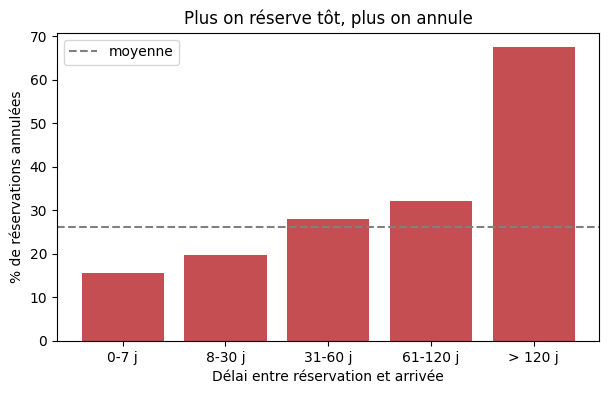

In [49]:
#graphique du taux par tranche
plt.figure(figsize=(7, 4))
plt.bar(results_tranche.index.astype(str), results_tranche['taux'], color='#C44E52')
plt.axhline(taux_global, color='grey', linestyle='--', label='moyenne')
plt.ylabel("% de réservations annulées")
plt.xlabel("Délai entre réservation et arrivée")
plt.title("Plus on réserve tôt, plus on annule")
plt.legend()
plt.show()

Conclusion Q2 : c’est l’inverse de l’idée reçue. Plus un client réserve tôt, plus il annule : 16 % à moins d’une semaine, 67 % au-delà de 4 mois. L’effet se retrouve même à segment égal.

Recommandation Q2 : pour les réservations faites plus de 60 jours avant l’arrivée, demander un acompte ou proposer un tarif non remboursable (avec une petite remise), ou fixer une date limite d’annulation gratuite (par exemple 30 jours avant l’arrivée).

**Q5:le modele de prédiction it's with knn:**

**Pourquoi KNN:**

*   prédire oui ou non (annulé ou pas) : c'est une classification dune categorie
*   Il donne une probabilité(important pour le block C)










In [50]:
#les imports
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, precision_score, recall_score

In [51]:
#Q5 : on utilise le fichier sans les anomalies (365 nuits, prix à 0 €)
chemin_modele = glob.glob('/content/**/reservations_modelisation_794*.csv', recursive=True)[0]
modele = pd.read_csv(chemin_modele)
modele['annule'] = (modele['a_annule'] == 'oui').astype(int)

print('Réservations :', len(modele))
print('Annulations :', modele['annule'].sum())
print('Taux :', round(modele['annule'].mean() * 100, 1), '%')

Réservations : 794
Annulations : 207
Taux : 26.1 %


In [52]:
#X = les informations connues au moment de la réservation (colonnes numériques)
#y = ce qu'on veut prédire
X = modele[['delai_reservation_j', 'nb_nuits', 'nb_personnes', 'prix_nuit_eur']]
y = modele['annule']

#70 % pour apprendre, 30 % pour tester, comme dans le cours (séance 3)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=42)

print('Apprentissage :', X_train.shape, '| Test :', X_test.shape)
print('Taux d\'annulation apprentissage / test :',
      round(y_train.mean() * 100, 1), '/', round(y_test.mean() * 100, 1))

Apprentissage : (555, 4) | Test : (239, 4)
Taux d'annulation apprentissage / test : 26.1 / 25.9


In [53]:
#on teste plusieurs k par validation croisée, sur l'apprentissage seulement
cv = StratifiedKFold(5, shuffle=True, random_state=42)

for k in [1, 3, 5, 11, 21, 31, 51]:
    knn = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    exactitude = cross_val_score(knn, X_train, y_train, cv=cv).mean()
    rappel = cross_val_score(knn, X_train, y_train, cv=cv, scoring='recall').mean()
    print(f'k = {k:2d} | exactitude = {exactitude:.2f} | rappel = {rappel:.2f}')

print('Repère : répondre "pas d\'annulation" à tout le monde donne 0.74 d\'exactitude')

k =  1 | exactitude = 0.66 | rappel = 0.34
k =  3 | exactitude = 0.67 | rappel = 0.22
k =  5 | exactitude = 0.71 | rappel = 0.16
k = 11 | exactitude = 0.72 | rappel = 0.10
k = 21 | exactitude = 0.73 | rappel = 0.04
k = 31 | exactitude = 0.73 | rappel = 0.00
k = 51 | exactitude = 0.74 | rappel = 0.00
Repère : répondre "pas d'annulation" à tout le monde donne 0.74 d'exactitude


In [54]:
#autant d'annulées que d'honorées dans l'apprentissage
apprentissage = X_train.copy()
apprentissage['annule'] = y_train
annulees = apprentissage[apprentissage['annule'] == 1]
honorees = apprentissage[apprentissage['annule'] == 0].sample(len(annulees), random_state=42)
equilibre = pd.concat([annulees, honorees])
print('Apprentissage équilibré :', len(equilibre), 'réservations (moitié annulées)')

#on compare deux jeux de colonnes et plusieurs k
jeux = {
    'délai seul': ['delai_reservation_j'],
    '4 colonnes': ['delai_reservation_j', 'nb_nuits', 'nb_personnes', 'prix_nuit_eur'],
}

for nom, colonnes in jeux.items():
    print('\n', nom)
    for k in [5, 11, 21, 31, 51, 71]:
        knn = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
        score = cross_val_score(knn, equilibre[colonnes], equilibre['annule'], cv=cv)
        print(f'  k = {k:2d} | justesse = {score.mean():.2f} (écart-type {score.std():.2f})')

print('\nRepère : 0.50 = pile ou face')

Apprentissage équilibré : 290 réservations (moitié annulées)

 délai seul
  k =  5 | justesse = 0.45 (écart-type 0.02)
  k = 11 | justesse = 0.53 (écart-type 0.06)
  k = 21 | justesse = 0.56 (écart-type 0.04)
  k = 31 | justesse = 0.59 (écart-type 0.03)
  k = 51 | justesse = 0.60 (écart-type 0.02)
  k = 71 | justesse = 0.59 (écart-type 0.03)

 4 colonnes
  k =  5 | justesse = 0.49 (écart-type 0.02)
  k = 11 | justesse = 0.50 (écart-type 0.05)
  k = 21 | justesse = 0.50 (écart-type 0.05)
  k = 31 | justesse = 0.54 (écart-type 0.04)
  k = 51 | justesse = 0.55 (écart-type 0.08)
  k = 71 | justesse = 0.55 (écart-type 0.06)

Repère : 0.50 = pile ou face


In [55]:
#on entraîne le modèle retenu sur l'apprentissage équilibré
knn_final = make_pipeline(StandardScaler(), KNeighborsClassifier(51))
knn_final.fit(equilibre[['delai_reservation_j']], equilibre['annule'])

#on le juge UNE SEULE FOIS sur le test, qu'il n'a jamais vu
prediction = knn_final.predict(X_test[['delai_reservation_j']])

print('Matrice de confusion :')
print(confusion_matrix(y_test, prediction))
print('Précision :', round(precision_score(y_test, prediction), 2))
print('Rappel    :', round(recall_score(y_test, prediction), 2))
print('Annulations dans le test :', y_test.sum(), 'sur', len(y_test))

Matrice de confusion :
[[119  58]
 [ 26  36]]
Précision : 0.38
Rappel    : 0.58
Annulations dans le test : 62 sur 239


In [56]:
#1. Vérification sur le test : la probabilité moyenne colle-t-elle au taux réel ?
knn_proba = make_pipeline(StandardScaler(), KNeighborsClassifier(51))
knn_proba.fit(X_train[['delai_reservation_j']], y_train)
proba_test = knn_proba.predict_proba(X_test[['delai_reservation_j']])[:, 1]
print('Probabilité moyenne prédite :', round(proba_test.mean() * 100, 1), '%')
print('Taux réel dans le test      :', round(y_test.mean() * 100, 1), '%')

#2. Modèle final sur toutes les réservations, puis export
knn_proba.fit(modele[['delai_reservation_j']], modele['annule'])
modele['proba_annulation'] = knn_proba.predict_proba(modele[['delai_reservation_j']])[:, 1].round(3)

export = modele[['reservation_id', 'hotel_id', 'segment_declare',
                 'delai_reservation_j', 'annule', 'proba_annulation']]
export = export.merge(hotels[['hotel_id', 'categorie']], on='hotel_id', how='left')
export.to_csv('q5_probabilites_annulation.csv', index=False)

print('Lignes exportées :', len(export))
display(export.head())

Probabilité moyenne prédite : 26.3 %
Taux réel dans le test      : 25.9 %
Lignes exportées : 794


,reservation_id,hotel_id,segment_declare,delai_reservation_j,annule,proba_annulation,categorie
0,R700357,H45,groupe,15.0,0,0.137,3 étoiles
1,R700658,H51,loisir,9.0,0,0.235,3 étoiles
2,R700649,H41,affaires,7.0,0,0.118,5 étoiles
3,R700732,H69,loisir,83.0,1,0.314,3 étoiles
4,R700098,H52,loisir,213.0,0,0.627,3 étoiles


**visualization des prédictions:**
vous pouvez chnager le (nouveau_delai) pour predire le taux d'annulation.
le k=51 c le resultats de la validation crosée

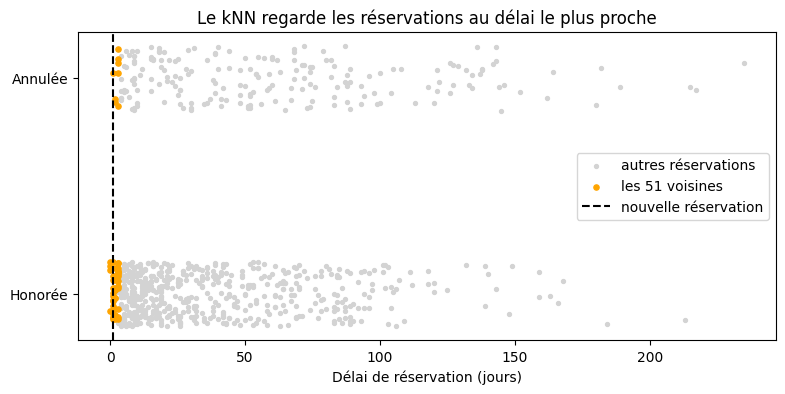

8 voisines annulées sur 51 → probabilité ≈ 16%


In [57]:
#schéma du kNN : x = délai, y = annulée ou honorée
import numpy as np

nouveau_delai = 1   # délai d'une nouvelle réservation (à changer pour tester)
k = 51

#les 51 réservations les plus proches en délai
distance = (modele['delai_reservation_j'] - nouveau_delai).abs()
voisines = distance.sort_values(kind='stable').index[:k]

#un petit décalage vertical aléatoire pour que les points ne se superposent pas
decalage = np.random.default_rng(42).uniform(-0.15, 0.15, len(modele))
y = modele['annule'] + decalage
est_voisine = modele.index.isin(voisines)

plt.figure(figsize=(9, 4))
plt.scatter(modele['delai_reservation_j'][~est_voisine], y[~est_voisine],
            s=8, color='lightgrey', label='autres réservations')
plt.scatter(modele['delai_reservation_j'][est_voisine], y[est_voisine],
            s=14, color='orange', label=f'les {k} voisines')
plt.axvline(nouveau_delai, color='black', linestyle='--', label='nouvelle réservation')
plt.yticks([0, 1], ['Honorée', 'Annulée'])
plt.xlabel('Délai de réservation (jours)')
plt.title('Le kNN regarde les réservations au délai le plus proche')
plt.legend()
plt.show()

nb_annulees = modele.loc[voisines, 'annule'].sum()
print(f'{nb_annulees} voisines annulées sur {k} → probabilité ≈ {nb_annulees / k:.0%}')

In [58]:
modele['groupe_proba'] = pd.qcut(modele['proba_annulation'], 4, duplicates='drop')
display(modele.groupby('groupe_proba', observed=True).agg(
    proba_moyenne=('proba_annulation', 'mean'),
    taux_reel=('annule', 'mean'),
    reservations=('annule', 'size')).round(2))

,proba_moyenne,taux_reel,reservations
groupe_proba,,,
"(0.038, 0.176]",0.14,0.14,263
"(0.176, 0.235]",0.22,0.23,151
"(0.235, 0.314]",0.28,0.30,200
"(0.314, 0.627]",0.43,0.42,180


In [59]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
